# Linear Algebra for ML

**Family:** Fundamentals | **Level:** Beginner | **Runs on:** CPU, under a minute

Vectors, matrices, projections and the SVD, which sit under regression and PCA.

## Learning objectives

- Compute dot products, norms and matrix products
- Solve a least squares problem with the normal equation
- See what the SVD does
- Connect these to regression and PCA

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ml_lab.data import load_dataset
from ml_lab.utils import set_seed
from ml_lab import visualization as viz
SEED = 42
set_seed(SEED)
viz.apply_style()

## 1. Vectors and matrices

The dot product measures alignment: $a\cdot b = \lVert a\rVert \lVert b\rVert \cos\theta$.

In [2]:
a, b = np.array([3.0, 4.0]), np.array([4.0, 3.0])
cos = a @ b / (np.linalg.norm(a) * np.linalg.norm(b))
print("norm of a:", np.linalg.norm(a), "| cosine:", round(float(cos), 3), "| angle (degrees):", round(float(np.degrees(np.arccos(cos))), 1))

norm of a: 5.0 | cosine: 0.96 | angle (degrees): 16.3


## 2. Least squares

Linear regression finds $\beta$ that minimises $\lVert y - X\beta\rVert^2$. The normal equation is $X^\top X\beta = X^\top y$. We use the real Auto MPG data.

In [3]:
df = load_dataset("auto_mpg").frame
X = np.c_[np.ones(len(df)), df[["weight", "horsepower"]].values]
y = df["mpg"].values
beta = np.linalg.solve(X.T @ X, X.T @ y)
print("coefficients (intercept, weight, horsepower):", np.round(beta, 4))
from sklearn.linear_model import LinearRegression
ref = LinearRegression().fit(df[["weight", "horsepower"]], y)
print("sklearn:", round(float(ref.intercept_), 4), np.round(ref.coef_, 4))

coefficients (intercept, weight, horsepower): [ 4.56402e+01 -5.80000e-03 -4.73000e-02]
sklearn: 45.6402 [-0.0058 -0.0473]


## 3. The SVD

Any matrix factors as $A = U S V^\top$. A low rank approximation keeps the largest singular values. We use the 8 by 8 digit images.

In [4]:
digits = load_dataset("digits").X.values
U, S, Vt = np.linalg.svd(digits - digits.mean(axis=0), full_matrices=False)
for k in [2, 5, 10, 20]:
    approx = (U[:, :k] * S[:k]) @ Vt[:k]
    err = np.linalg.norm(digits - digits.mean(axis=0) - approx) / np.linalg.norm(digits - digits.mean(axis=0))
    print(f"rank {k}: relative error {err:.3f}")

rank 2: relative error 0.846
rank 5: relative error 0.675
rank 10: relative error 0.512
rank 20: relative error 0.325


## 4. A picture of rank 10

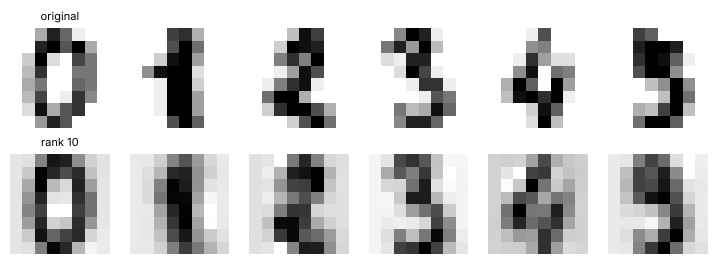

In [5]:
k = 10
approx = (U[:, :k] * S[:k]) @ Vt[:k] + digits.mean(axis=0)
fig, axes = plt.subplots(2, 6, figsize=(9, 3))
for i in range(6):
    axes[0, i].imshow(digits[i].reshape(8, 8), cmap="gray_r"); axes[0, i].axis("off")
    axes[1, i].imshow(approx[i].reshape(8, 8), cmap="gray_r"); axes[1, i].axis("off")
axes[0, 0].set_title("original", fontsize=8); axes[1, 0].set_title("rank 10", fontsize=8); plt.show()

## Exercises

1. Show that the normal equation fails when two columns are identical, and fix it with `np.linalg.lstsq`.
2. Compute the condition number of `X.T @ X` for the Auto MPG design matrix before and after standardising.

## Summary

- Regression is a projection problem.
- SVD gives the best low rank approximation.
- Scale features to keep matrices well conditioned.

**Next:** Probability and statistics.

**Data note.** Real datasets come from `ml_lab.data` with licence notes in `datasets/catalog`. Synthetic numbers appear only where a demonstration needs controlled data, and are labelled.